# 第11章：间隔与核的数值含义

**学生实验｜全书深化稿**

## 背景与数据
二维人工点用于间隔示意，Wine用于C和gamma的少量联合验证。

## 本次要回答的问题
核对显式二次映射，再解释参数组合的不同验证表现。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 11: margins, kernels and a controlled C/gamma experiment."""
import numpy as np
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from common import *

def run():
    X,y,_=development('wine');splits=list(cv5().split(X,y));rows=[]
    for C in [.1,1.,10.]:
        for gamma in [.01,.1,1.]:
            model=make_pipeline(StandardScaler(),SVC(C=C,gamma=gamma,kernel='rbf'))
            scores=cross_val_score(model,X,y,cv=splits)
            rows.append({'C':C,'gamma':gamma,'validation_accuracy':scores.mean(),'fold_std':scores.std()})
    df=table('ch11_grid',rows);show_result(df)
    plt.figure(figsize=(6.4,4))
    for C in [.1,1.,10.]:
        d=df[df.C==C];plt.semilogx(d.gamma,d.validation_accuracy,'o-',label=f'C={C}')
    plt.xlabel('RBF gamma');plt.ylabel('五折验证准确率');plt.legend();figure('v3_ch11_grid')
    # A hand-constructed nonlinear problem, with no held-out scientific interpretation.
    xx=np.array([[-2,0],[0,-2],[2,0],[0,2],[.2,0],[0,.2],[-.2,0],[0,-.2]])
    yy=np.array([1,1,1,1,0,0,0,0])
    lin=SVC(kernel='linear',C=100).fit(xx,yy);rbf=SVC(kernel='rbf',C=100,gamma=1).fit(xx,yy)
    dump('ch11_nonlinear',{'linear_training_accuracy':lin.score(xx,yy),'rbf_training_accuracy':rbf.score(xx,yy)})
    a=np.array([1.,2.]);b=np.array([3.,-1.]);phi=lambda v:np.array([v[0]**2,np.sqrt(2)*v[0]*v[1],v[1]**2])
    assert np.isclose(phi(a)@phi(b),(a@b)**2)
    table('ch11_kernel_check',[{'explicit_feature_dot':phi(a)@phi(b),'squared_original_dot':(a@b)**2}])

In [3]:
result = run()
if result is not None:
    print(result)

   C  gamma  validation_accuracy  fold_std
 0.1   0.01             0.493350  0.036271
 0.1   0.10             0.965271  0.030846
 0.1   1.00             0.401232  0.010256
 1.0   0.01             0.979064  0.017100
 1.0   0.10             0.993103  0.013793
 1.0   1.00             0.555419  0.063215
10.0   0.01             0.978818  0.017301
10.0   0.10             0.985961  0.017199
10.0   1.00             0.598030  0.051398


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch11_grid.png


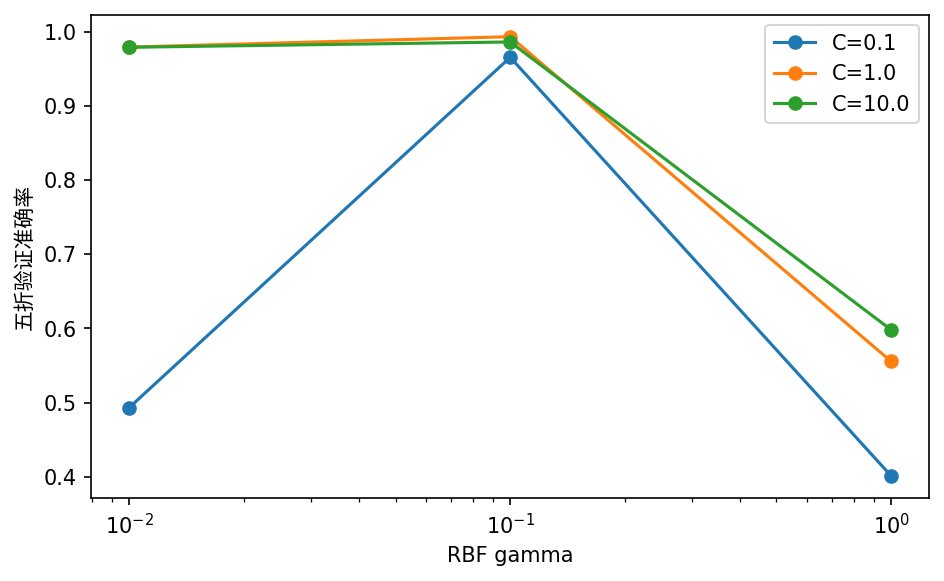

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch11_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

核对显式二次映射，再解释参数组合的不同验证表现。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。